In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_parquet("data_optimized.parquet")

In [ ]:
df.shape

(590540, 434)

In [ ]:
df.columns

Index(['isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1',
       'card2', 'card3', 'card4', 'card5', 'card6',
       ...
       'id_31', 'id_32', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38',
       'DeviceType', 'DeviceInfo'],
      dtype='object', length=434)

In [ ]:
df.head()

,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,0,86400,68.5,W,13926,361.0,150.0,discover,142.0,credit,...,Missing,-999.0,Missing,Missing,Missing,Missing,Missing,Missing,Missing,Missing
1,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,...,Missing,-999.0,Missing,Missing,Missing,Missing,Missing,Missing,Missing,Missing
2,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,...,Missing,-999.0,Missing,Missing,Missing,Missing,Missing,Missing,Missing,Missing
3,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,...,Missing,-999.0,Missing,Missing,Missing,Missing,Missing,Missing,Missing,Missing
4,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 434 entries, isFraud to DeviceInfo
dtypes: category(32), float32(399), int16(1), int32(1), int8(1)
memory usage: 922.6 MB


In [ ]:
y=df['isFraud']
x=df.drop('isFraud',axis=1)
print(x.shape)
print(y.shape)

(590540, 433)
(590540,)


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
isFraud,0
TransactionDT,0
TransactionAmt,0
ProductCD,0
card1,0
...,...
id_36,0
id_37,0
id_38,0
DeviceType,0


In [ ]:
df.duplicated().sum()

np.int64(3)

In [ ]:
df=df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
isFraud,int8
TransactionDT,int32
TransactionAmt,float32
ProductCD,category
card1,int16
...,...
id_36,category
id_37,category
id_38,category
DeviceType,category


In [ ]:
df.select_dtypes(include='object').columns

Index([], dtype='object')

check target distribution

In [ ]:
df['isFraud'].value_counts()

,count
isFraud,
0,569874
1,20663


Check Percentage

In [ ]:
df['isFraud'].value_counts(normalize=True)*100

,proportion
isFraud,
0,96.500981
1,3.499019


Visualize Class Imbalance

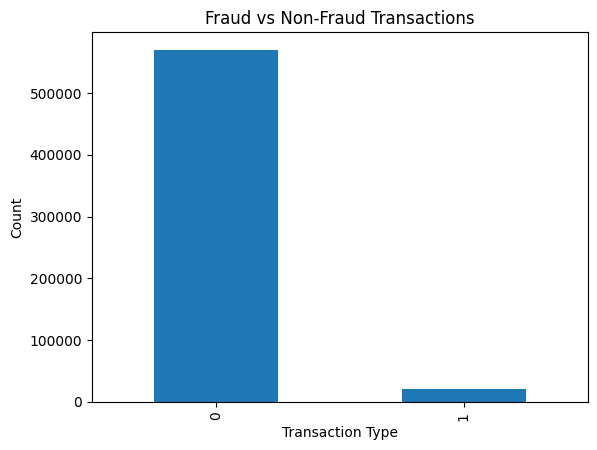

In [ ]:
import matplotlib.pyplot as plt
df['isFraud'].value_counts().plot(kind='bar')
plt.title('Fraud vs Non-Fraud Transactions')
plt.xlabel('Transaction Type')
plt.ylabel('Count')
plt.show()

In [ ]:
y=df['isFraud']
X=df.drop(['isFraud'],axis=1,errors='ignore')

Train-Test-Split

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print(X_train.shape)
print(X_test.shape)

(472429, 433)
(118108, 433)


In [ ]:
X_train.head()

,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
63265,1443679,150.000,H,15066,170.0,150.0,mastercard,102.0,credit,315.0,...,chrome 63.0,24.0,Missing,match_status:2,T,F,T,T,desktop,Windows
190491,4266396,117.000,W,5170,184.0,150.0,visa,226.0,debit,325.0,...,Missing,-999.0,Missing,Missing,Missing,Missing,Missing,Missing,Missing,Missing
196154,4408849,250.000,W,6019,583.0,150.0,visa,226.0,credit,441.0,...,Missing,-999.0,Missing,Missing,Missing,Missing,Missing,Missing,Missing,Missing
462532,11901950,39.000,W,10616,583.0,150.0,visa,226.0,credit,472.0,...,Missing,-999.0,Missing,Missing,Missing,Missing,Missing,Missing,Missing,Missing
442666,11238432,26.559,C,1164,545.0,185.0,visa,137.0,debit,299.0,...,chrome 60.0 for android,-999.0,Missing,Missing,F,F,T,F,mobile,SM-J500M Build/LMY48B


In [ ]:
y_train.value_counts()

,count
isFraud,
0,455899
1,16530


Model Training

In [ ]:
df=df.sample(50000,random_state=42)

In [ ]:
X=df.drop('isFraud',axis=1)
y=df['isFraud']

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
X=pd.get_dummies(X)

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
model=DecisionTreeClassifier()
model.fit(X_train,y_train)

DecisionTreeClassifier()

Make Prediction

In [ ]:
y_pred=model.predict(X_test)

Check Model Accuracy

In [ ]:
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test,y_pred)
print("Model accuracy:",accuracy*100)

Model accuracy: 95.64


Classification report

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      9653
           1       0.39      0.43      0.41       347

    accuracy                           0.96     10000
   macro avg       0.68      0.70      0.69     10000
weighted avg       0.96      0.96      0.96     10000



Confusion Matrix

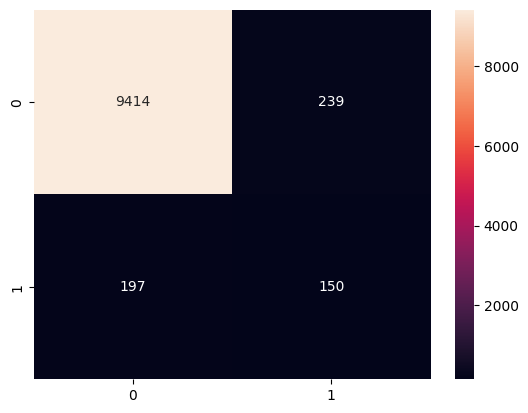

In [ ]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt='d')
plt.show()

Feature Importance

In [ ]:
importance=pd.Series(model.feature_importances_,index=X_train.columns)
importance.sort_values(ascending=False).head(10)

,0
V201,0.092277
TransactionDT,0.032758
C12,0.031231
C13,0.031079
TransactionAmt,0.026616
C1,0.026500
card1,0.024540
V317,0.021124
card2,0.017862
dist1,0.017182


Feature Importance Graph

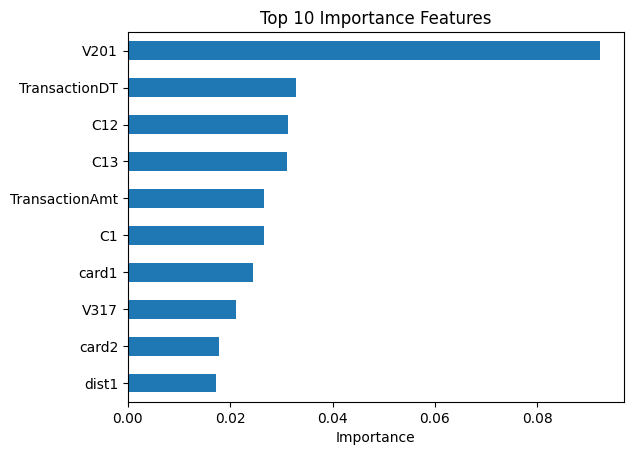

In [ ]:
importance.sort_values().tail(10).plot(kind='barh')
plt.title('Top 10 Importance Features')
plt.xlabel('Importance')
plt.show()


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      9653
           1       0.39      0.43      0.41       347

    accuracy                           0.96     10000
   macro avg       0.68      0.70      0.69     10000
weighted avg       0.96      0.96      0.96     10000



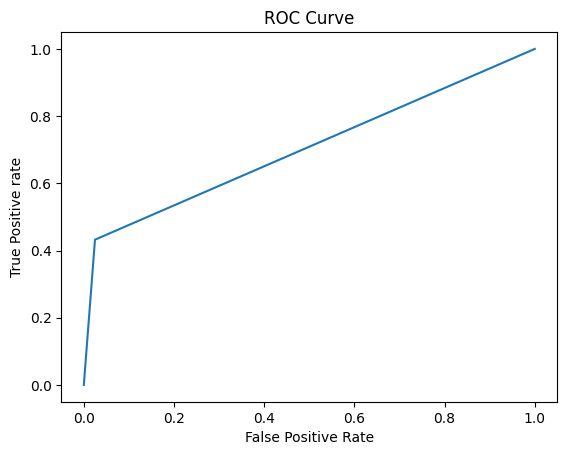

In [ ]:
from sklearn.metrics import roc_curve
y_prob=model.predict_proba(X_test)[:,1]
fpr,tpr,_=roc_curve(y_test,y_prob)
plt.plot(fpr,tpr)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.show()
